<a href="https://colab.research.google.com/github/psar0006/NBA_Models/blob/main/NBA_Rbds_Model_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NBA Player Rebounds Prediction — V1
**Research notebook | LightGBM conditional mean + Negative Binomial probabilities**

This notebook preserves the original modelling experiments and their results, while organising the workflow from historical feature engineering through model selection, probabilistic calibration, diagnostics, and V1 model export.

**Reading guide:** Run cells in order within each stage. Some experiments are alternatives rather than steps required for production inference. Existing code and outputs have been retained; the added explanations do not imply that the models have been rerun or independently validated.

**V1 scope:** The rebounds model and conditional dispersion model are retained as developed. Integrating separately predicted pregame minutes is deferred to V2.

---
## 1. Data ingestion and pregame feature engineering
Prepare historical player-game data and construct predictors based on previous games.

In [ ]:
##Import Data

import polars as pl
import numpy as np
import kagglehub
import datetime as dt
from kagglehub import KaggleDatasetAdapter



lf_player_stats = kagglehub.dataset_load(
    KaggleDatasetAdapter.POLARS,
    "eoinamoore/historical-nba-data-and-player-box-scores",
    "PlayerStatisticsExtended.csv",
    polars_kwargs={
        "schema_overrides": {
            "seriesGameNumber": pl.String,
            "numMinutes": pl.String,

            # Basic box score statistics
            "points": pl.Float64,
            "reboundsDefensive": pl.Float64,
            "reboundsOffensive": pl.Float64,
            "reboundsTotal": pl.Float64,
            "foulsPersonal": pl.Float64,
            "assists": pl.Float64,
            "steals": pl.Float64,
            "blocks": pl.Float64,
            "turnovers": pl.Float64,

            # Shooting
            "fieldGoals": pl.Float64,
            "fieldGoalsAttempted": pl.Float64,
            "fieldGoalsMade": pl.Float64,
            "fieldGoalsPercentage": pl.Float64,

            "threePointersMade": pl.Float64,
            "threePointersAttempted": pl.Float64,
            "threePointersPercentage": pl.Float64,

            "freeThrowsMade": pl.Float64,
            "freeThrowsAttempted": pl.Float64,
            "freeThrowsPercentage": pl.Float64,

            "plusMinusPoints": pl.Float64,

            # Advanced statistics
            "offensiveRating": pl.Float64,
            "defensiveRating": pl.Float64,
            "assistPercentage": pl.Float64,
            "assistToTurnoverRatio": pl.Float64,
            "assistRatio": pl.Float64,
            "offensiveReboundPercentage": pl.Float64,
            "defensiveReboundPercentage": pl.Float64,
            "reboundPercentage": pl.Float64,
            "estimatedTurnoverPercentage": pl.Float64,
            "effectiveFieldGoalPercentage": pl.Float64,
            "usagePercentage": pl.Float64,
            "pace": pl.Float64,
            "pacePer40": pl.Float64,

            # Percentage of team production
            "percentTeamOffensiveRebounds": pl.Float64,
            "percentTeamDefensiveRebounds": pl.Float64,
            "percentTeamBlocks": pl.Float64,
            "percentTeamPoints": pl.Float64,
        }
    }
)





lf_team_stats = kagglehub.dataset_load(
  KaggleDatasetAdapter.POLARS,
  "eoinamoore/historical-nba-data-and-player-box-scores",
  "TeamStatisticsExtended.csv"

  # Provide any additional arguments like
  # sql_query, polars_frame_type, or
  # polars_kwargs.
  # See the documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpolars
)


100%|██████████| 435M/435M [00:06<00:00, 68.4MB/s]


100%|██████████| 36.6M/36.6M [00:00<00:00, 45.7MB/s]


### 1.1 Initial data cleaning
Standardise source fields and establish the base player-game dataset used downstream.

In [ ]:
## ============================================================
# BASIC CLEANING OF DATA
# ============================================================


# ============================================================
# 1. CONVERT numMinutes FROM MM:SS TO DECIMAL MINUTES
# ============================================================

lf_player_stats = lf_player_stats.with_columns(
    pl.when(
        pl.col("numMinutes").is_not_null()
        & pl.col("numMinutes").str.contains(":")
    )
    .then(
        pl.col("numMinutes")
        .str.split_exact(":", 1)
        .struct.field("field_0")
        .cast(pl.Float64)
        +
        (
            pl.col("numMinutes")
            .str.split_exact(":", 1)
            .struct.field("field_1")
            .cast(pl.Float64)
            / 60
        )
    )
    .otherwise(
        pl.col("numMinutes").cast(pl.Float64, strict=False)
    )
    .alias("numMinutes")
)


# ============================================================
# 2. SELECT RELEVANT COLUMNS
# ============================================================

lf_player_stats = lf_player_stats.select(

    # --------------------------------------------------------
    # Identifiers
    # --------------------------------------------------------
    "personId",
    "gameId",
    "gameDateTimeEst",

    # --------------------------------------------------------
    # Team / opponent
    # --------------------------------------------------------
    "playerteamCity",
    "playerteamName",
    "playerteamId",

    "opponentteamCity",
    "opponentteamName",
    "opponentteamId",

    "home",

    # --------------------------------------------------------
    # Basic player box score
    # --------------------------------------------------------
    "numMinutes",
    "points",
    "assists",
    "blocks",
    "steals",

    "fieldGoalsAttempted",
    "fieldGoalsMade",
    "fieldGoalsPercentage",

    "threePointersAttempted",
    "threePointersMade",
    "threePointersPercentage",

    "freeThrowsAttempted",
    "freeThrowsMade",
    "freeThrowsPercentage",

    "reboundsDefensive",
    "reboundsOffensive",
    "reboundsTotal",

    "turnovers",
    "foulsPersonal",
    "plusMinusPoints",

    # --------------------------------------------------------
    # Advanced player statistics
    # --------------------------------------------------------
    "offensiveRating",
    "defensiveRating",

    "assistPercentage",
    "assistToTurnoverRatio",
    "assistRatio",

    "offensiveReboundPercentage",
    "defensiveReboundPercentage",
    "reboundPercentage",

    "estimatedTurnoverPercentage",
    "effectiveFieldGoalPercentage",

    "usagePercentage",

    "pace",
    "pacePer40",

    # --------------------------------------------------------
    # Percentage of team production
    # --------------------------------------------------------
    "percentTeamOffensiveRebounds",
    "percentTeamDefensiveRebounds",
    "percentTeamBlocks",
    "percentTeamPoints",

    # --------------------------------------------------------
    # Player / game context
    # --------------------------------------------------------
    "startingPosition",
    "gameType",
    "comment"
)


# ============================================================
# 3. CONVERT GAME DATE
# ============================================================

lf_player_stats = (
    lf_player_stats
    .with_columns(
        pl.col("gameDateTimeEst")
        .str.to_datetime("%Y-%m-%d %H:%M:%S")
        .dt.date()
    )
    .filter(
        pl.col("gameDateTimeEst") >= dt.date(1996, 11, 1)
    )
)


# ============================================================
# 4. CREATE STARTER INDICATOR
# ============================================================

lf_player_stats = lf_player_stats.with_columns(
    (
        pl.col("startingPosition").is_not_null()
        &
        (pl.col("startingPosition") != "")
    )
    .cast(pl.Int8)
    .alias("is_starter")
)


# ============================================================
# 5. CREATE PRE-GAME AVAILABILITY INDICATOR
# ============================================================
# Temporary historical proxy until NBA lineup rosterStatus
# data is integrated.
#
# 1 = Available
# 0 = Unavailable due to injury / illness etc.
# ============================================================

lf_player_stats = lf_player_stats.with_columns(

    pl.when(
        pl.col("comment")
        .fill_null("")
        .str.to_lowercase()
        .str.contains(
            r"injur|illness|sick|concussion|sprain|strain|soreness|"
            r"fracture|broken|surgery|rehab|recovery|contusion|"
            r"tendinitis|tendonitis|inflammation|infection|"
            r"back spasms|personal reasons"
        )
    )
    .then(0)
    .otherwise(1)
    .cast(pl.Int8)
    .alias("pregame_available")
)


# ============================================================
# 6. KEEP REGULAR-SEASON GAMES ONLY
# ============================================================

lf_player_stats = lf_player_stats.filter(
    ~pl.col("gameType").is_in([
        "Pre Season",
        "Post Season",
        "All-Star Game",
        "Preseason",
        "Playoffs"
    ])
)

### 1.2 Historical offensive and form features
Construct lagged, rolling and exponentially weighted player statistics. Confirm that each predictor is available **before** the game being forecast.

In [ ]:
import polars as pl

# ============================================================
# CONFIGURATION AND HELPER FUNCTIONS
# ============================================================
ALPHA = 0.60
WINDOWS = (5, 10, 20)
GAME_KEYS = ["gameId", "playerteamId"]
PLAYER_SORT = ["personId", "gameDateTimeEst", "gameId"]
TEAM_SORT = ["playerteamId", "gameDateTimeEst", "gameId"]

def add_history(lf, metrics, group_col, sort_cols, windows=WINDOWS):
    """Create strictly prior-game lag, EWMA and rolling averages."""
    lf = lf.sort(sort_cols)
    lf = lf.with_columns([
        pl.col(m).shift(1).over(group_col).alias(f"{m}_lag1")
        for m in metrics
    ])
    lf = lf.with_columns([
        pl.col(m).shift(1).ewm_mean(
            alpha=ALPHA, adjust=False, ignore_nulls=True
        ).over(group_col).alias(f"{m}_ewma")
        for m in metrics
    ])
    for w in windows:
        lf = lf.with_columns([
            pl.col(m).shift(1).rolling_mean(
                window_size=w, min_samples=1
            ).over(group_col).alias(f"{m}_avg{w}")
            for m in metrics
        ])
    return lf

def ratio(numerator, denominator, name):
    return (
        pl.when(pl.col(denominator) > 0)
        .then(pl.col(numerator) / pl.col(denominator))
        .otherwise(None)
        .alias(name)
    )

# ============================================================
# 1. HISTORICAL TEAM-GAME TOTALS
# ============================================================
# Include all players in a completed game, not only rotation players.
# Require both teams to have completed player-box-score records.
# A scheduled-game row with null outcomes is excluded here.

lf_completed = lf_player_stats.filter(
    pl.col("reboundsTotal").is_not_null()
    & pl.col("fieldGoalsAttempted").is_not_null()
)

SUM_METRICS = [
    "reboundsDefensive", "reboundsOffensive", "reboundsTotal",
    "fieldGoalsAttempted", "fieldGoalsMade",
    "threePointersAttempted", "threePointersMade",
    "freeThrowsAttempted", "freeThrowsMade",
]

lf_team_actual = (
    lf_completed
    .group_by(["gameId", "gameDateTimeEst", "playerteamId", "opponentteamId"])
    .agg(
        [pl.col(m).sum().alias(f"team_{m}") for m in SUM_METRICS]
        + [
            pl.col("pace").mean().alias("team_pace"),
            pl.col("personId").n_unique().alias("team_players_used"),
        ]
    )
)

# Opponent actual game stats, to compute team rebound rates.
lf_opp_actual = lf_team_actual.select(
    ["gameId", pl.col("playerteamId").alias("opponentteamId")]
    + [
        pl.col(f"team_{m}").alias(f"opp_{m}")
        for m in SUM_METRICS
    ]
)

lf_team_actual = lf_team_actual.join(
    lf_opp_actual, on=["gameId", "opponentteamId"], how="left"
)

# ============================================================
# 2. TEAM SHOOTING, REBOUNDING AND OPPORTUNITY
# ============================================================
lf_team_actual = lf_team_actual.with_columns([
    ratio("team_fieldGoalsMade", "team_fieldGoalsAttempted", "team_fg_pct"),
    ratio("team_threePointersMade", "team_threePointersAttempted", "team_3p_pct"),
    ratio("team_freeThrowsMade", "team_freeThrowsAttempted", "team_ft_pct"),
    (pl.col("team_fieldGoalsAttempted") - pl.col("team_fieldGoalsMade")).alias("team_fg_missed"),
    (pl.col("team_threePointersAttempted") - pl.col("team_threePointersMade")).alias("team_3p_missed"),
    (pl.col("team_freeThrowsAttempted") - pl.col("team_freeThrowsMade")).alias("team_ft_missed"),
    (pl.col("opp_fieldGoalsAttempted") - pl.col("opp_fieldGoalsMade")).alias("opp_fg_missed"),
    (pl.col("opp_threePointersAttempted") - pl.col("opp_threePointersMade")).alias("opp_3p_missed"),
    (pl.col("opp_freeThrowsAttempted") - pl.col("opp_freeThrowsMade")).alias("opp_ft_missed"),
])

lf_team_actual = lf_team_actual.with_columns([
    (pl.col("team_fg_missed") + pl.col("opp_fg_missed")).alias("rebound_chances_proxy"),
    pl.col("team_fg_missed").alias("offensive_chances_proxy"),
    pl.col("opp_fg_missed").alias("defensive_chances_proxy"),
    (
        pl.when((pl.col("team_reboundsOffensive") + pl.col("opp_reboundsDefensive")) > 0)
        .then(
            pl.col("team_reboundsOffensive") /
            (pl.col("team_reboundsOffensive") + pl.col("opp_reboundsDefensive"))
        ).otherwise(None)
    ).alias("team_oreb_pct"),
    (
        pl.when((pl.col("team_reboundsDefensive") + pl.col("opp_reboundsOffensive")) > 0)
        .then(
            pl.col("team_reboundsDefensive") /
            (pl.col("team_reboundsDefensive") + pl.col("opp_reboundsOffensive"))
        ).otherwise(None)
    ).alias("team_dreb_pct"),
])

# Missed FGs are a proxy for rebound opportunities, not an exact count.
# 3P misses are a SUBSET of FG misses: do not add them again.

TEAM_METRICS = (
    [f"team_{m}" for m in SUM_METRICS]
    + [
        "team_pace", "team_fg_pct", "team_3p_pct", "team_ft_pct",
        "team_fg_missed", "team_3p_missed", "team_ft_missed",
        "opp_fg_missed", "opp_3p_missed", "opp_ft_missed",
        "team_oreb_pct", "team_dreb_pct",
        "rebound_chances_proxy", "offensive_chances_proxy",
        "defensive_chances_proxy",
    ]
)

# ============================================================
# 3. TEAM TIMELINE: COMPLETED + SCHEDULED GAMES
# ============================================================
# One row per team/game even for scheduled games. Joining
# historical actuals by gameId leaves future outcome fields null.
# With ignore_nulls=True for EWMA, null future rows must not be
# interspersed before completed games in the training history.

lf_team_schedule = (
    lf_player_stats.select(
        "gameId", "gameDateTimeEst", "playerteamId", "opponentteamId"
    ).unique()
)
lf_team_timeline = lf_team_schedule.join(
    lf_team_actual.select(["gameId", "playerteamId"] + TEAM_METRICS),
    on=GAME_KEYS, how="left"
)

# Rolling operations below use only completed games for each team:
# a scheduled game receives features from earlier completed games.
# We forward-join the most recent *completed* team snapshot,
# where the snapshot includes that game's actual statistics.
#
# For historical games, we use lagged features computed on the
# completed-only timeline; for future games, we use the latest
# available completed snapshot strictly before tipoff.

lf_team_history = add_history(
    lf_team_actual, TEAM_METRICS, "playerteamId", TEAM_SORT
)
TEAM_HIST_COLS = [
    c for c in lf_team_history.collect_schema().names()
    if c.endswith("_lag1") or c.endswith("_ewma")
    or any(c.endswith(f"_avg{w}") for w in WINDOWS)
]

# Historical rows: exact match to own completed game.
lf_team_historical_features = lf_team_history.select(
    ["gameId", "playerteamId"] + TEAM_HIST_COLS
)

# For scheduled rows, recompute snapshots inclusive of the most
# recently completed game, by shifting the historical features
# forward one team-game. A simple alternative is using a
# backward as-of join with *inclusive* snapshots.
#
# Build inclusive snapshot metrics directly on completed games.
lf_team_snapshot = lf_team_actual.sort(TEAM_SORT)
lf_team_snapshot = lf_team_snapshot.with_columns([
    pl.col(m).ewm_mean(
        alpha=ALPHA, adjust=False, ignore_nulls=True
    ).over("playerteamId").alias(f"{m}_ewma")
    for m in TEAM_METRICS
])
for w in WINDOWS:
    lf_team_snapshot = lf_team_snapshot.with_columns([
        pl.col(m).rolling_mean(window_size=w, min_samples=1)
        .over("playerteamId").alias(f"{m}_avg{w}")
        for m in TEAM_METRICS
    ])
lf_team_snapshot = lf_team_snapshot.with_columns([
    pl.col(m).alias(f"{m}_lag1") for m in TEAM_METRICS
])

lf_team_snapshot = lf_team_snapshot.select(
    ["playerteamId", "gameDateTimeEst", "gameId"] + TEAM_HIST_COLS
)

# Join strictly earlier games, not the current game. We use
# timestamp + gameId ordering via asof with a strict timestamp
# requirement; dates tied at the same instant are excluded.
# Existing cleaning casts gameDateTimeEst to Date.
# That conservatively excludes all games on the same date.
lf_team_asof = (
    lf_team_timeline
    .sort(["gameDateTimeEst", "playerteamId"])
    .join_asof(
        lf_team_snapshot.sort(["gameDateTimeEst", "playerteamId"]),
        on="gameDateTimeEst",
        by="playerteamId",
        strategy="backward",
        allow_exact_matches=False,
        suffix="_snapshot",
    )
)

# Use exact historical feature rows for completed games, and
# as-of snapshots for scheduled rows.
lf_team_features = lf_team_asof.join(
    lf_team_historical_features,
    on=["gameId", "playerteamId"],
    how="left",
    suffix="_historical",
)
lf_team_features = lf_team_features.with_columns([
    pl.coalesce(
        pl.col(f"{c}_historical"),
        pl.col(c)
    ).alias(c)
    for c in TEAM_HIST_COLS
]).drop([f"{c}_historical" for c in TEAM_HIST_COLS])

# ============================================================
# 4. JOIN BOTH TEAMS' PREGAME HISTORIES TO PLAYERS
# ============================================================
lf_own_features = lf_team_features.select(
    ["gameId", "playerteamId"] + TEAM_HIST_COLS
)
lf_opponent_features = lf_team_features.select(
    ["gameId", pl.col("playerteamId").alias("opponentteamId")]
    + [pl.col(c).alias(f"opponent_{c}") for c in TEAM_HIST_COLS]
)

lf_player_stats = (
    lf_player_stats
    .join(lf_own_features, on=["gameId", "playerteamId"], how="left")
    .join(lf_opponent_features, on=["gameId", "opponentteamId"], how="left")
)

# ============================================================
# 5. PLAYER REBOUND SHARE AND FORM
# ============================================================
lf_player_stats = lf_player_stats.join(
    lf_team_actual.select([
        "gameId", "playerteamId",
        "team_reboundsTotal", "team_reboundsOffensive",
        "team_reboundsDefensive",
    ]),
    on=["gameId", "playerteamId"],
    how="left",
)

lf_player_stats = lf_player_stats.with_columns([
    ratio("reboundsTotal", "team_reboundsTotal", "player_rebound_share"),
    ratio("reboundsOffensive", "team_reboundsOffensive", "player_oreb_share"),
    ratio("reboundsDefensive", "team_reboundsDefensive", "player_dreb_share"),
    (
        pl.when(pl.col("numMinutes") > 0)
        .then(pl.col("reboundsTotal") * 36 / pl.col("numMinutes"))
        .otherwise(None)
    ).alias("rebounds_per36"),
])

PLAYER_METRICS = [
    "numMinutes", "reboundsTotal", "reboundsOffensive",
    "reboundsDefensive", "player_rebound_share",
    "player_oreb_share", "player_dreb_share",
    "rebounds_per36", "pace",
    "fieldGoalsAttempted", "threePointersAttempted",
]

lf_player_stats = add_history(
    lf_player_stats, PLAYER_METRICS, "personId", PLAYER_SORT,
    windows=(5, 10)
)
lf_player_stats = lf_player_stats.with_columns([
    (pl.col("reboundsTotal_avg5") - pl.col("reboundsTotal_avg10"))
    .alias("rebounds_trend_5v10"),
    (pl.col("player_rebound_share_avg5") - pl.col("player_rebound_share_avg10"))
    .alias("rebound_share_trend_5v10"),
    (pl.col("numMinutes_avg5") - pl.col("numMinutes_avg10"))
    .alias("minutes_trend_5v10"),
])

print("Team, opponent, player rebound-share and historical features defined.")


Team, opponent, player rebound-share and historical features defined.


### 1.3 Vacated rebounding opportunity from confirmed pregame absences
A key rebounder's absence can redistribute opportunities, but their historical rebounds are not mechanically transferred to another player.
The next cell defines a reusable join for a separate historical or live pregame roster feed. This is intentionally not derived from comment or box-score participation: those fields cannot establish what was known before tipoff. Without that feed, the output remains null rather than inventing availability.

In [ ]:
# ============================================================
# OPTIONAL: CONFIRMED PREGAME ROSTER AVAILABILITY
# ============================================================
# Supply lf_roster_availability separately when available.
#
# Required columns:
#   gameId, playerteamId, personId, pregame_available
#   reboundsTotal_ewma, reboundsOffensive_ewma,
#   reboundsDefensive_ewma, player_rebound_share_avg5
#
# IMPORTANT: these EWMA/share values must be computed using
# history strictly before the game; availability must reflect
# a timestamped pre-tipoff status, not final box-score comments.

VACATED_FEATURES = [
    "inactive_rebounders_count",
    "vacated_rebounds_ewma",
    "vacated_oreb_ewma",
    "vacated_dreb_ewma",
    "vacated_rebound_share",
    "unknown_availability_count",
]

if "lf_roster_availability" in globals():
    required = {
        "gameId", "playerteamId", "personId", "pregame_available",
        "reboundsTotal_ewma", "reboundsOffensive_ewma",
        "reboundsDefensive_ewma", "player_rebound_share_avg5",
    }
    missing = required - set(lf_roster_availability.collect_schema().names())
    if missing:
        raise ValueError(f"Roster availability missing columns: {sorted(missing)}")

    lf_vacated = (
        lf_roster_availability
        .group_by(["gameId", "playerteamId"])
        .agg([
            (
                (pl.col("pregame_available") == 0)
                & (pl.col("reboundsTotal_ewma") >= 5)
            ).sum().alias("inactive_rebounders_count"),
            *[
                pl.when(pl.col("pregame_available") == 0)
                .then(pl.col(source).fill_null(0))
                .otherwise(0).sum().alias(dest)
                for source, dest in [
                    ("reboundsTotal_ewma", "vacated_rebounds_ewma"),
                    ("reboundsOffensive_ewma", "vacated_oreb_ewma"),
                    ("reboundsDefensive_ewma", "vacated_dreb_ewma"),
                    ("player_rebound_share_avg5", "vacated_rebound_share"),
                ]
            ],
            pl.col("pregame_available").is_null().sum()
            .alias("unknown_availability_count"),
        ])
    )
    lf_player_stats = lf_player_stats.join(
        lf_vacated, on=["gameId", "playerteamId"], how="left"
    )
else:
    lf_player_stats = lf_player_stats.with_columns([
        pl.lit(None, dtype=pl.Float64).alias(c) for c in VACATED_FEATURES
    ])
    print("No verified pregame roster feed: vacated-rebound features set to null.")


No verified pregame roster feed: vacated-rebound features set to null.


### 1.4 Final feature assembly
Select offensive and defensive features and create the modelling LazyFrame.

In [ ]:
# ============================================================
# REBOUND MODEL FEATURE ASSEMBLY
# ============================================================
TARGET = "reboundsTotal"

PLAYER_FEATURES = [
    f"{m}_{suffix}"
    for m in PLAYER_METRICS
    for suffix in ("lag1", "ewma", "avg5", "avg10")
] + [
    "rebounds_trend_5v10",
    "rebound_share_trend_5v10",
    "minutes_trend_5v10",
]

TEAM_FEATURES = [
    c for c in TEAM_HIST_COLS
    if c.endswith(("_ewma", "_avg5", "_avg10", "_avg20"))
]

OPPONENT_FEATURES = [f"opponent_{c}" for c in TEAM_FEATURES]

# Do not enable VACATED_FEATURES until you have a validated
# pregame availability feed covering historical training rows.
REBOUNDS_FEATURES = (
    PLAYER_FEATURES + TEAM_FEATURES + OPPONENT_FEATURES
)

ID_COLS = [
    "personId", "gameId", "gameDateTimeEst",
    "playerteamId", "opponentteamId", "home",
]

lf_player_stats_rebounds = (
    lf_player_stats
    .filter(
        pl.col(TARGET).is_not_null()
        & pl.col("numMinutes").is_not_null()
        & (pl.col("numMinutes") > 0)
    )
    .select(ID_COLS + [TARGET] + REBOUNDS_FEATURES)
    .sort(["gameDateTimeEst", "gameId", "personId"])
)

print(f"Rebounds target: {TARGET}")
print(f"Pregame feature count: {len(REBOUNDS_FEATURES)}")
print("Model frame: lf_player_stats_rebounds")

# Optional sanity checks:
# print(lf_player_stats_rebounds.select(
#     ["personId", "gameId", TARGET,
#      "reboundsTotal_ewma", "player_rebound_share_avg5",
#      "opponent_team_fg_missed_avg5"]
# ).head(10).collect())


Rebounds target: reboundsTotal
Pregame feature count: 239
Model frame: lf_player_stats_rebounds


### 1.5 Feature engineering sanity check
Materialise the prepared dataset for inspection. This may be memory-intensive on the full historical dataset.

In [ ]:
print(lf_player_stats_rebounds.select(
     ["personId", "gameId", TARGET,
      "reboundsTotal_ewma", "player_rebound_share_avg5",
      "opponent_team_fg_missed_avg5"]
 ).head(10).collect())

<sys>:0: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided


shape: (10, 6)
┌──────────┬──────────┬───────────────┬────────────────────┬───────────────────┬───────────────────┐
│ personId ┆ gameId   ┆ reboundsTotal ┆ reboundsTotal_ewma ┆ player_rebound_sh ┆ opponent_team_fg_ │
│ ---      ┆ ---      ┆ ---           ┆ ---                ┆ are_avg5          ┆ missed_avg5       │
│ i64      ┆ i64      ┆ f64           ┆ f64                ┆ ---               ┆ ---               │
│          ┆          ┆               ┆                    ┆ f64               ┆ f64               │
╞══════════╪══════════╪═══════════════╪════════════════════╪═══════════════════╪═══════════════════╡
│ 23       ┆ 29600001 ┆ 13.0          ┆ null               ┆ null              ┆ null              │
│ 26       ┆ 29600001 ┆ 1.0           ┆ null               ┆ null              ┆ null              │
│ 54       ┆ 29600001 ┆ 0.0           ┆ null               ┆ null              ┆ null              │
│ 70       ┆ 29600001 ┆ 1.0           ┆ null               ┆ null           

---
## 2. Model development and benchmarking
Explore training windows and candidate regression algorithms before choosing a mean-prediction model.

### 2.1 Optional environment setup
Install H2O if needed. Dependency-installation commands are environment-specific and may be skipped when packages are already available.

In [ ]:
# H2O is optional and RUN_H2O=False. No installation required.


In [ ]:
# ============================================================
# 6.1 IMPORTS AND MODELLING CONFIGURATION
# ============================================================
# Install in your notebook environment if needed:
# %pip install lightgbm xgboost scikit-learn pandas joblib
# Optional: %pip install h2o

import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

RANDOM_STATE = 42
RUN_H2O = False             # Set True after installing H2O and Java
RUN_ABLATIONS = True
N_JOBS = 4                  # Adjust for your machine
TEST_FRACTION = 0.15
VALIDATION_FRACTION = 0.15

# Optional: restrict the modelling period, while preserving
# feature history generated from earlier seasons.
MIN_MODEL_DATE = None       # e.g. "2020-10-01"

# ============================================================
# 6.2 MATERIALISE AND VALIDATE FEATURE FRAME
# ============================================================
df = lf_player_stats_rebounds.collect().to_pandas()

if MIN_MODEL_DATE is not None:
    df = df.loc[
        pd.to_datetime(df["gameDateTimeEst"]) >= pd.Timestamp(MIN_MODEL_DATE)
    ].copy()

df["gameDateTimeEst"] = pd.to_datetime(df["gameDateTimeEst"])
df = df.sort_values(["gameDateTimeEst", "gameId", "personId"]).reset_index(drop=True)

assert not df.empty, "No training rows found."
assert df["reboundsTotal"].notna().all()
assert (df["reboundsTotal"] >= 0).all()

# Avoid accidental duplicates caused by source data or joins.
dup = df.duplicated(["personId", "gameId"]).sum()
if dup:
    raise ValueError(f"Found {dup} duplicate player-game rows; inspect joins.")

# Pre-game features only: no current-game outcomes, IDs or minutes.
X = df[REBOUNDS_FEATURES].copy()
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan).astype("float32")
y = df["reboundsTotal"].astype("float32")

# Remove all-null features: they provide no learning signal.
all_null = X.columns[X.isna().all()].tolist()
if all_null:
    warnings.warn(f"Dropping {len(all_null)} entirely-null features: {all_null[:10]}")
    X = X.drop(columns=all_null)

FEATURES_USED = X.columns.tolist()
print(f"Rows: {len(df):,} | Features: {len(FEATURES_USED)}")
print(f"Date range: {df.gameDateTimeEst.min().date()} to {df.gameDateTimeEst.max().date()}")
print(f"Target mean: {y.mean():.3f} | Target median: {y.median():.1f}")


<sys>:0: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided


Rows: 732,425 | Features: 239
Date range: 1996-11-01 to 2026-11-02
Target mean: 4.163 | Target median: 3.0


In [ ]:
# ============================================================
# 6.3 CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================
unique_dates = np.array(sorted(df["gameDateTimeEst"].dt.normalize().unique()))
n_dates = len(unique_dates)
train_end = int(n_dates * (1 - VALIDATION_FRACTION - TEST_FRACTION))
val_end = int(n_dates * (1 - TEST_FRACTION))

if train_end < 30 or val_end <= train_end or val_end >= n_dates:
    raise ValueError("Insufficient distinct game dates for 70/15/15 chronological split.")

train_cutoff = unique_dates[train_end]
test_cutoff = unique_dates[val_end]
dates = df["gameDateTimeEst"].dt.normalize().to_numpy()

train_mask = dates < train_cutoff
val_mask = (dates >= train_cutoff) & (dates < test_cutoff)
test_mask = dates >= test_cutoff

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

print("Chronological split:")
for name, mask in [("Train", train_mask), ("Validation", val_mask), ("Test", test_mask)]:
    part = df.loc[mask]
    print(f"  {name:10s}: {len(part):>8,} rows | "
          f"{part.gameDateTimeEst.min().date()} to {part.gameDateTimeEst.max().date()} | "
          f"mean REB {part.reboundsTotal.mean():.3f}")
print("The test set will not be used for model selection.")


Chronological split:
  Train     :  508,239 rows | 1996-11-01 to 2017-11-26 | mean REB 4.159
  Validation:  110,555 rows | 2017-11-27 to 2022-03-02 | mean REB 4.231
  Test      :  113,631 rows | 2022-03-03 to 2026-11-02 | mean REB 4.111
The test set will not be used for model selection.


In [ ]:
# ============================================================
# 6.4 METRICS AND SIMPLE PREGAME BASELINES
# ============================================================
def regression_metrics(y_true, pred):
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred),
        "Bias_actual_minus_pred": float(np.mean(np.asarray(y_true) - pred)),
    }

results = []
validation_predictions = {}

for name, col in [
    ("EWMA baseline", "reboundsTotal_ewma"),
    ("Last-5 baseline", "reboundsTotal_avg5"),
    ("Last-10 baseline", "reboundsTotal_avg10"),
]:
    if col not in X.columns:
        continue
    # Use train mean for cold-start players; do not learn from validation targets.
    fallback = float(y_train.mean())
    pred = X_val[col].fillna(fallback).to_numpy()
    results.append({"Model": name, **regression_metrics(y_val, pred),
                    "Fit_seconds": 0.0})
    validation_predictions[name] = np.clip(pred, 0, None)

display(pd.DataFrame(results).sort_values("MAE"))


,Model,MAE,RMSE,R2,Bias_actual_minus_pred,Fit_seconds
2,Last-10 baseline,1.966719,2.597266,0.445860,0.017227,0.0
1,Last-5 baseline,2.018638,2.665900,0.416186,0.011065,0.0
0,EWMA baseline,2.145644,2.848046,0.333683,0.006539,0.0


In [ ]:
# ============================================================
# 6.5 TRAIN LIGHTGBM AND XGBOOST
# ============================================================
# Both models handle NaNs natively.
# Conservative initial hyperparameters; tune only after benchmarking.
# We do not use the test set for early stopping or tuning.

MODEL_FACTORIES = {
    "LightGBM": lambda: LGBMRegressor(
        objective="regression",
        n_estimators=650,
        learning_rate=0.04,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=75,
        colsample_bytree=0.85,
        subsample=0.85,
        subsample_freq=1,
        reg_lambda=1.0,
        verbosity=-1,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    ),
    "XGBoost": lambda: XGBRegressor(
        objective="reg:squarederror",
        n_estimators=650,
        learning_rate=0.04,
        max_depth=5,
        min_child_weight=10,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    ),
}

trained_models = {}
for name, factory in MODEL_FACTORIES.items():
    print(f"Starting {name} ...")
    t0 = time.perf_counter()
    model = factory()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    pred = np.clip(model.predict(X_val), 0, None)
    validation_predictions[name] = pred
    trained_models[name] = model
    scores = regression_metrics(y_val, pred)
    results.append({"Model": name, **scores, "Fit_seconds": elapsed})
    print(f"Finished {name} | MAE={scores['MAE']:.4f} | "
          f"RMSE={scores['RMSE']:.4f} | R²={scores['R2']:.4f} | "
          f"{elapsed:.1f}s")

validation_results = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(validation_results)


Starting LightGBM ...
Finished LightGBM | MAE=1.9375 | RMSE=2.5458 | R²=0.4676 | 272.1s
Starting XGBoost ...
Finished XGBoost | MAE=1.9428 | RMSE=2.5470 | R²=0.4671 | 328.0s


,Model,MAE,RMSE,R2,Bias_actual_minus_pred,Fit_seconds
0,LightGBM,1.937465,2.545819,0.467595,0.015266,272.060963
1,XGBoost,1.942782,2.546972,0.467113,-0.010131,327.992436
2,Last-10 baseline,1.966719,2.597266,0.445860,0.017227,0.000000
3,Last-5 baseline,2.018638,2.665900,0.416186,0.011065,0.000000
4,EWMA baseline,2.145644,2.848046,0.333683,0.006539,0.000000



LightGBM top 25:


,Model,Feature,Total_gain,Splits,Gain_pct
7,LightGBM,reboundsTotal_avg10,2.685949e+07,510,76.645201
6,LightGBM,reboundsTotal_avg5,2.665487e+06,186,7.606129
19,LightGBM,player_rebound_share_avg10,1.599624e+06,271,4.564624
1,LightGBM,numMinutes_ewma,2.928986e+05,441,0.835804
17,LightGBM,player_rebound_share_ewma,2.515240e+05,244,0.717739
18,LightGBM,player_rebound_share_avg5,1.881043e+05,164,0.536767
5,LightGBM,reboundsTotal_ewma,1.660337e+05,170,0.473787
0,LightGBM,numMinutes_lag1,1.433072e+05,261,0.408936
43,LightGBM,threePointersAttempted_avg10,1.363527e+05,233,0.389091
41,LightGBM,threePointersAttempted_ewma,7.330279e+04,256,0.209174


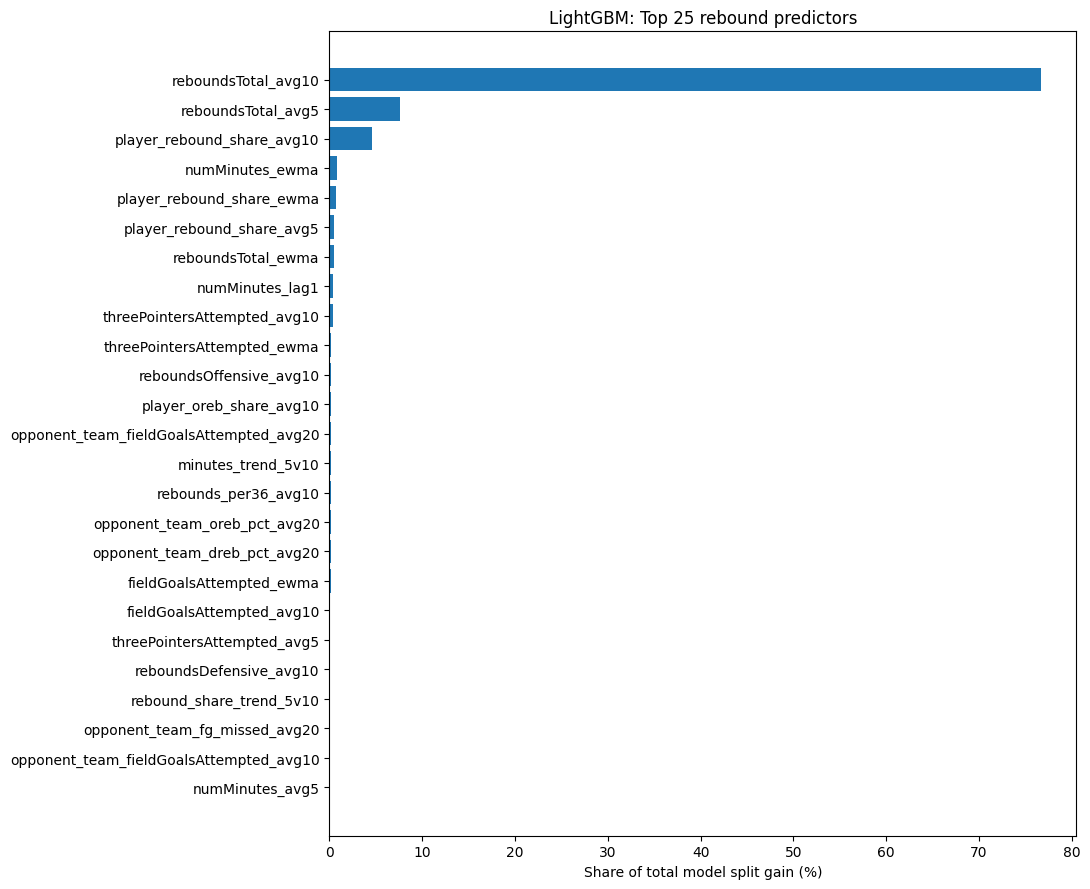


XGBoost top 25:


,Model,Feature,Total_gain,Splits,Gain_pct
7,XGBoost,reboundsTotal_avg10,2.821036e+07,503.0,81.677853
6,XGBoost,reboundsTotal_avg5,1.868745e+06,307.0,5.410605
19,XGBoost,player_rebound_share_avg10,1.028646e+06,344.0,2.978254
1,XGBoost,numMinutes_ewma,2.855574e+05,453.0,0.826779
17,XGBoost,player_rebound_share_ewma,2.664418e+05,306.0,0.771433
18,XGBoost,player_rebound_share_avg5,2.206802e+05,241.0,0.638939
5,XGBoost,reboundsTotal_ewma,1.831190e+05,252.0,0.530187
0,XGBoost,numMinutes_lag1,1.417677e+05,302.0,0.410462
43,XGBoost,threePointersAttempted_avg10,1.298198e+05,255.0,0.375869
23,XGBoost,player_oreb_share_avg10,7.348066e+04,280.0,0.212750


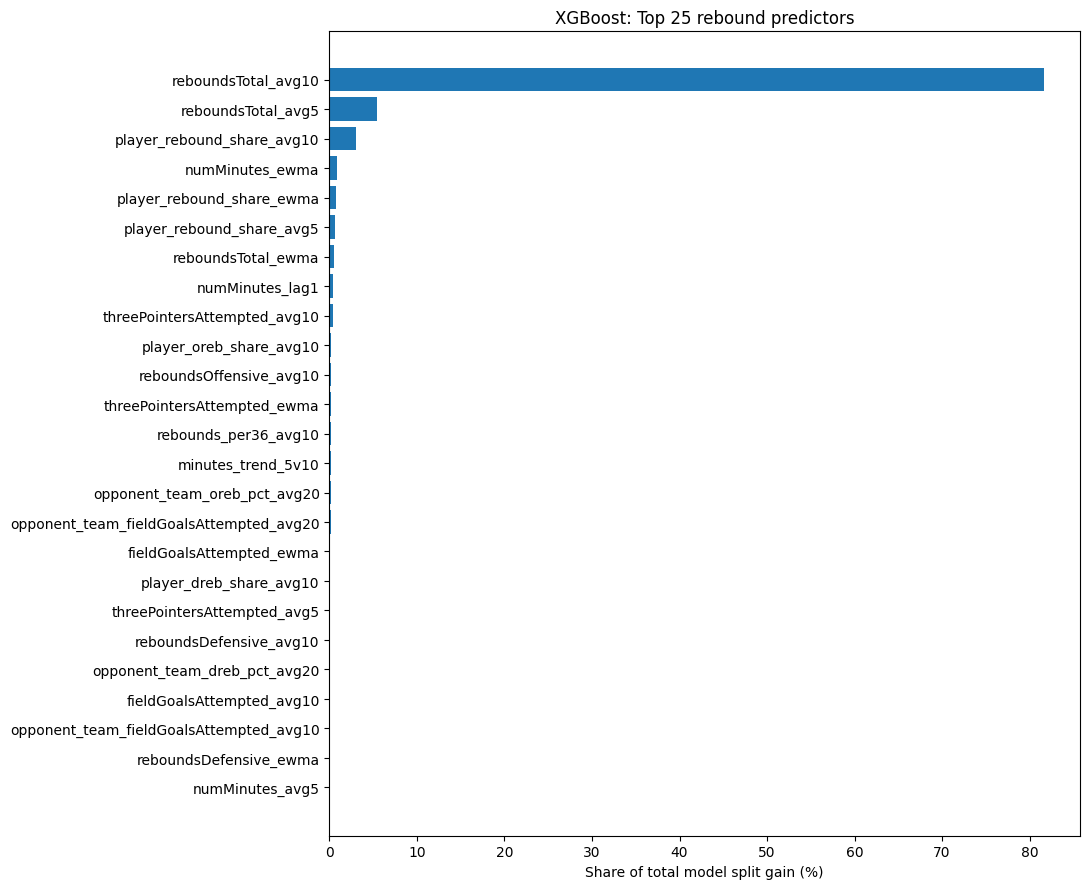

In [ ]:
# ============================================================
# 6.7 FEATURE IMPORTANCE: GAIN AND SPLIT COUNTS
# ============================================================
import matplotlib.pyplot as plt

importance_frames = []
for name, model in trained_models.items():
    if name == "LightGBM":
        gain = model.booster_.feature_importance(importance_type="gain")
        split = model.booster_.feature_importance(importance_type="split")
    else:
        booster = model.get_booster()
        gain_map = booster.get_score(importance_type="total_gain")
        split_map = booster.get_score(importance_type="weight")
        gain = np.array([gain_map.get(f, 0.0) for f in FEATURES_USED])
        split = np.array([split_map.get(f, 0.0) for f in FEATURES_USED])

    imp = pd.DataFrame({
        "Model": name,
        "Feature": FEATURES_USED,
        "Total_gain": gain,
        "Splits": split,
    })
    total = imp["Total_gain"].sum()
    imp["Gain_pct"] = 100 * imp["Total_gain"] / total if total > 0 else 0
    importance_frames.append(imp)
    print(f"\n{name} top 25:")
    display(imp.sort_values("Total_gain", ascending=False).head(25))

    top = imp.nlargest(25, "Total_gain").sort_values("Gain_pct")
    plt.figure(figsize=(11, 9))
    plt.barh(top["Feature"], top["Gain_pct"])
    plt.xlabel("Share of total model split gain (%)")
    plt.title(f"{name}: Top 25 rebound predictors")
    plt.tight_layout()
    plt.show()

feature_importance = pd.concat(importance_frames, ignore_index=True)


In [ ]:
# ============================================================
# 6.8 VALIDATION ERROR BY ACTUAL REBOUND BUCKET
# ============================================================
bucket_edges = [-0.1, 2.5, 5.5, 8.5, 11.5, np.inf]
bucket_labels = ["0-2", "3-5", "6-8", "9-11", "12+"]

bucket = pd.cut(y_val, bins=bucket_edges, labels=bucket_labels)
bucket_rows = []
for name, pred in validation_predictions.items():
    tmp = pd.DataFrame({
        "bucket": bucket.to_numpy(),
        "actual": y_val.to_numpy(),
        "pred": np.asarray(pred),
    })
    for group, part in tmp.groupby("bucket", observed=True):
        bucket_rows.append({
            "Model": name, "Actual_REB_bucket": str(group),
            "N": len(part),
            "MAE": np.mean(np.abs(part["actual"] - part["pred"])),
            "Bias_actual_minus_pred": np.mean(part["actual"] - part["pred"]),
        })

bucket_errors = pd.DataFrame(bucket_rows)
display(bucket_errors)


,Model,Actual_REB_bucket,N,MAE,Bias_actual_minus_pred
0,EWMA baseline,0-2,40743,1.765255,-1.499727
1,EWMA baseline,12+,4728,4.909780,4.446527
2,EWMA baseline,3-5,38294,1.750540,-0.106259
3,EWMA baseline,6-8,19022,2.520013,1.308435
4,EWMA baseline,9-11,7768,3.489384,2.572493
5,Last-5 baseline,0-2,40743,1.732971,-1.546408
6,Last-5 baseline,12+,4728,4.863230,4.567375
7,Last-5 baseline,3-5,38294,1.548347,-0.089888
8,Last-5 baseline,6-8,19022,2.329128,1.348549
9,Last-5 baseline,9-11,7768,3.343676,2.629258


In [ ]:
# ============================================================
# 6.9 FEATURE GROUP ABLATIONS (OPTIONAL)
# ============================================================
ablation_results = []
if RUN_ABLATIONS:
    groups = {
        "All features": FEATURES_USED,
        "Player only": [f for f in FEATURES_USED if f in PLAYER_FEATURES],
        "Player + own team": [
            f for f in FEATURES_USED if f in PLAYER_FEATURES or f in TEAM_FEATURES
        ],
        "Player + opponent": [
            f for f in FEATURES_USED if f in PLAYER_FEATURES or f in OPPONENT_FEATURES
        ],
        "Without rebound share": [
            f for f in FEATURES_USED
            if not any(token in f for token in (
                "rebound_share", "oreb_share", "dreb_share"
            ))
        ],
        "Without shooting environment": [
            f for f in FEATURES_USED
            if not any(token in f for token in (
                "fieldGoals", "threePointers", "freeThrows",
                "fg_pct", "3p_pct", "ft_pct",
                "fg_missed", "3p_missed", "ft_missed",
                "chances_proxy"
            ))
        ],
    }
    for group_name, cols in groups.items():
        if not cols:
            continue
        m = MODEL_FACTORIES["LightGBM"]()
        m.fit(X_train[cols], y_train)
        pred = np.clip(m.predict(X_val[cols]), 0, None)
        ablation_results.append({
            "Feature_set": group_name,
            "N_features": len(cols),
            **regression_metrics(y_val, pred)
        })
    ablation_df = pd.DataFrame(ablation_results).sort_values("MAE")
    display(ablation_df)


,Feature_set,N_features,MAE,RMSE,R2,Bias_actual_minus_pred
1,Player only,47,1.927250,2.553605,0.464334,0.154969
2,Player + own team,143,1.932436,2.550369,0.465691,0.096044
4,Without rebound share,226,1.936512,2.545944,0.467543,0.022342
0,All features,239,1.937465,2.545819,0.467595,0.015266
5,Without shooting environment,87,1.939261,2.549799,0.465929,0.024508
3,Player + opponent,143,1.939987,2.546835,0.467171,-0.005979


In [ ]:
# ============================================================
# 7.1 SELECT, REFIT, AND EVALUATE ON TEST
# ============================================================
eligible = validation_results.loc[
    validation_results["Model"].isin(MODEL_FACTORIES)
].sort_values("MAE")
if eligible.empty:
    raise RuntimeError("No LightGBM/XGBoost model available to select.")

BEST_MODEL_NAME = str(eligible.iloc[0]["Model"])
print("Selected mean model:", BEST_MODEL_NAME)

X_trainval = X.loc[train_mask | val_mask]
y_trainval = y.loc[train_mask | val_mask]

final_mean_model = MODEL_FACTORIES[BEST_MODEL_NAME]()
t0 = time.perf_counter()
final_mean_model.fit(X_trainval, y_trainval)
print(f"Final refit took {time.perf_counter() - t0:.1f}s")

test_pred = np.clip(final_mean_model.predict(X_test), 0, None)
test_metrics = regression_metrics(y_test, test_pred)
print("Untouched test results:", test_metrics)

test_diagnostics = df.loc[test_mask, [
    "personId", "gameId", "gameDateTimeEst",
    "playerteamId", "opponentteamId", "reboundsTotal"
]].copy()
test_diagnostics["predicted_rebounds"] = test_pred
test_diagnostics["error_actual_minus_pred"] = (
    test_diagnostics["reboundsTotal"] - test_diagnostics["predicted_rebounds"]
)
display(test_diagnostics.head(20))


Selected mean model: LightGBM
Final refit took 326.3s
Untouched test results: {'MAE': 1.9260317580626274, 'RMSE': np.float64(2.529186027613254), 'R2': 0.45130446384489487, 'Bias_actual_minus_pred': -0.048710820376292895}


,personId,gameId,gameDateTimeEst,playerteamId,opponentteamId,reboundsTotal,predicted_rebounds,error_actual_minus_pred
618794,101150,22100710,2022-03-03,NaN,NaN,0.0,1.853349,-1.853349
618795,201568,22100710,2022-03-03,NaN,NaN,5.0,5.454157,-0.454157
618796,201942,22100710,2022-03-03,NaN,NaN,7.0,6.315016,0.684984
618797,202684,22100710,2022-03-03,NaN,NaN,5.0,4.187314,0.812686
618798,202696,22100710,2022-03-03,NaN,NaN,11.0,10.825012,0.174988
618799,203476,22100710,2022-03-03,NaN,NaN,2.0,1.997966,0.002034
618800,203897,22100710,2022-03-03,NaN,NaN,3.0,4.317382,-1.317382
618801,203991,22100710,2022-03-03,NaN,NaN,11.0,10.337310,0.662690
618802,203992,22100710,2022-03-03,NaN,NaN,4.0,4.329851,-0.329851
618803,1626153,22100710,2022-03-03,NaN,NaN,3.0,3.533278,-0.533278


In [ ]:
# ============================================================
# 7.2 EXPORT MEAN MODEL AND METADATA
# ============================================================
import json
import joblib

OUT_DIR = Path("models/nba_rebounds/v1")
OUT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(final_mean_model, OUT_DIR / "rebounds_mean_model.joblib")
feature_importance.to_csv(OUT_DIR / "feature_importance.csv", index=False)
validation_results.to_csv(OUT_DIR / "validation_comparison.csv", index=False)
test_diagnostics.to_csv(OUT_DIR / "test_predictions.csv", index=False)

metadata = {
    "target": "reboundsTotal",
    "model": BEST_MODEL_NAME,
    "features": FEATURES_USED,
    "alpha_ewma": ALPHA,
    "train_cutoff_exclusive": str(pd.Timestamp(train_cutoff).date()),
    "test_cutoff_inclusive": str(pd.Timestamp(test_cutoff).date()),
    "trainval_rows": int(len(X_trainval)),
    "test_rows": int(len(X_test)),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "availability_features_enabled": False,
    "notes": "Pregame historical form features only; conditional NB not fitted yet.",
}
(OUT_DIR / "model_config.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
print("Saved artifacts to:", OUT_DIR.resolve())


Saved artifacts to: /content/models/nba_rebounds/v1


In [ ]:
# ============================================================
# 9.1 NEGATIVE BINOMIAL HELPERS AND PRICING
# ============================================================
from scipy.optimize import minimize_scalar
from scipy.stats import nbinom, poisson
from scipy.special import gammaln
import numpy as np
import pandas as pd

EPS = 1e-9
ALPHA_MIN, ALPHA_MAX = 1e-4, 5.0


def nb2_nll(y, mu, alpha):
    """Per-observation NB2 negative log likelihood; α > 0."""
    y = np.asarray(y, dtype=float)
    mu = np.maximum(np.asarray(mu, dtype=float), EPS)
    a = np.maximum(np.asarray(alpha, dtype=float), ALPHA_MIN)
    r = 1.0 / a
    return -(
        gammaln(y + r) - gammaln(r) - gammaln(y + 1)
        + r * (np.log(r) - np.log(r + mu))
        + y * (np.log(mu) - np.log(r + mu))
    )


def fit_global_alpha(y, mu):
    y = np.asarray(y, dtype=float)
    mu = np.maximum(np.asarray(mu, dtype=float), EPS)
    opt = minimize_scalar(
        lambda log_a: float(np.mean(nb2_nll(y, mu, np.exp(log_a)))),
        bounds=(np.log(ALPHA_MIN), np.log(ALPHA_MAX)),
        method="bounded", options={"xatol": 1e-4},
    )
    if not opt.success:
        raise RuntimeError(f"Global dispersion fit failed: {opt.message}")
    return float(np.exp(opt.x))


def fit_bucket_alphas(y, mu, global_alpha, edges=(0, 3, 6, 9, 13, np.inf),
                      min_bucket_n=250, prior_n=500):
    """Fit bucket NB2 alpha; shrink toward global alpha for stability."""
    y = np.asarray(y, dtype=float)
    mu = np.asarray(mu, dtype=float)
    bucket_ids = np.digitize(mu, edges[1:-1], right=False)
    alphas = []
    diagnostics = []
    for k in range(len(edges) - 1):
        idx = bucket_ids == k
        count = int(idx.sum())
        local = fit_global_alpha(y[idx], mu[idx]) if count >= min_bucket_n else global_alpha
        weight = count / (count + prior_n) if count >= min_bucket_n else 0.0
        blended = float(np.exp(weight * np.log(local) + (1 - weight) * np.log(global_alpha)))
        alphas.append(blended)
        diagnostics.append({"bucket": k, "lower": edges[k], "upper": edges[k + 1],
                            "n": count, "raw_alpha": local, "shrunk_alpha": blended})
    return {"edges": list(edges), "alphas": alphas}, pd.DataFrame(diagnostics)


def bucket_alpha(mu, spec):
    mu = np.asarray(mu, dtype=float)
    idx = np.digitize(mu, spec["edges"][1:-1], right=False)
    return np.asarray(spec["alphas"])[idx]


def prop_probabilities(mu, line, distribution="nb", alpha=None):
    """Return win/push/loss probabilities for BOTH sides, incl. integer lines.

    For integer lines, a result equal to the line is a push.
    For half-point lines, push probability is zero.
    """
    mu = np.maximum(np.asarray(mu, dtype=float), EPS)
    line = np.asarray(line, dtype=float)
    mu, line = np.broadcast_arrays(mu, line)
    if np.any(line < 0):
        raise ValueError("Prop lines must be nonnegative")
    floor_line = np.floor(line)
    ceil_line = np.ceil(line)
    if distribution == "poisson":
        cdf = lambda k: poisson.cdf(k, mu)
        sf = lambda k: poisson.sf(k, mu)
        pmf = lambda k: poisson.pmf(k, mu)
    elif distribution == "nb":
        if alpha is None:
            raise ValueError("alpha is required for NB")
        a = np.maximum(np.broadcast_to(np.asarray(alpha, dtype=float), mu.shape), ALPHA_MIN)
        r = 1.0 / a
        p = r / (r + mu)
        cdf = lambda k: nbinom.cdf(k, r, p)
        sf = lambda k: nbinom.sf(k, r, p)
        pmf = lambda k: nbinom.pmf(k, r, p)
    else:
        raise ValueError("distribution must be 'poisson' or 'nb'")
    over = sf(floor_line)   # P(Y > line)
    under = cdf(ceil_line - 1)  # P(Y < line)
    push = np.where(floor_line == line, pmf(line), 0.0)
    return {"over": over, "under": under, "push": push}


def fair_odds(win_probability, push_probability=0):
    """Fair decimal odds with stake returned on push: (1-push)/p(win)."""
    win_probability = np.asarray(win_probability, dtype=float)
    push_probability = np.asarray(push_probability, dtype=float)
    return np.where(win_probability > 0,
                    (1 - push_probability) / np.maximum(win_probability, EPS), np.inf)


def expected_roi(win_probability, push_probability, bookmaker_odds):
    """Per-unit-stake EV: p(win)*(odds-1) - p(loss)."""
    return (np.asarray(win_probability) * (np.asarray(bookmaker_odds) - 1)
            - (1 - np.asarray(win_probability) - np.asarray(push_probability)))


In [ ]:
# ============================================================
# 9.2 EXPANDING-WINDOW OOF MEAN PREDICTIONS
# ============================================================
# Uses X, y, df, train_mask, val_mask, test_mask and
# MODEL_FACTORIES from the model-development cells above.

PROB_MODEL_NAME = "LightGBM"
PROB_FEATURES = [f for f in PLAYER_FEATURES if f in X.columns]
# To use all features instead, set:
# PROB_FEATURES = FEATURES_USED

N_OOF_FOLDS = 4
OOF_WARMUP_FRACTION = 0.40


def expanding_oof_predictions(X_subset, y_subset, dates_subset,
                              feature_names, n_folds=N_OOF_FOLDS,
                              warmup_fraction=OOF_WARMUP_FRACTION):
    dates = pd.to_datetime(pd.Series(dates_subset).reset_index(drop=True)).dt.normalize()
    distinct = np.array(sorted(dates.unique()))
    warmup = max(20, int(len(distinct) * warmup_fraction))
    if len(distinct) - warmup < n_folds:
        raise ValueError("Insufficient dates for chronological OOF folds")
    boundaries = np.linspace(warmup, len(distinct), n_folds + 1, dtype=int)
    X_local = X_subset[feature_names].reset_index(drop=True)
    y_local = pd.Series(y_subset).reset_index(drop=True)
    preds = np.full(len(X_local), np.nan)
    for fold in range(n_folds):
        lo, hi = boundaries[fold], boundaries[fold + 1]
        train_idx = (dates < distinct[lo]).to_numpy()
        hold_idx = ((dates >= distinct[lo]) &
                    (dates < distinct[hi] if hi < len(distinct) else True)).to_numpy()
        model = MODEL_FACTORIES[PROB_MODEL_NAME]()
        model.fit(X_local.loc[train_idx], y_local.loc[train_idx])
        preds[hold_idx] = np.maximum(model.predict(X_local.loc[hold_idx]), EPS)
        print(f"OOF fold {fold + 1}/{n_folds}: train={train_idx.sum():,} "
              f"holdout={hold_idx.sum():,}")
    valid = np.isfinite(preds)
    return preds, valid

# Build OOF strictly within the training dates.
train_dates = df.loc[train_mask, "gameDateTimeEst"].reset_index(drop=True)
train_oof, train_oof_valid = expanding_oof_predictions(
    X_train, y_train, train_dates, PROB_FEATURES
)
print(f"OOF coverage: {train_oof_valid.sum():,}/{len(train_oof):,}")


OOF fold 1/4: train=196,148 holdout=75,918
OOF fold 2/4: train=272,066 holdout=75,670
OOF fold 3/4: train=347,736 holdout=80,138
OOF fold 4/4: train=427,874 holdout=80,365
OOF coverage: 312,091/508,239


In [ ]:
# ============================================================
# 9.3 FIT DISPERSION ON TRAINING OOF PREDICTIONS ONLY
# ============================================================
train_oof_y = y_train.to_numpy()[train_oof_valid]
train_oof_mu = train_oof[train_oof_valid]
alpha_train = fit_global_alpha(train_oof_y, train_oof_mu)
bucket_train, bucket_train_diagnostics = fit_bucket_alphas(
    train_oof_y, train_oof_mu, alpha_train
)
print(f"Training OOF global alpha: {alpha_train:.5f}")
display(bucket_train_diagnostics)

# Refit a mean model on ALL training rows, predict validation.
prob_mean_train = MODEL_FACTORIES[PROB_MODEL_NAME]()
prob_mean_train.fit(X_train[PROB_FEATURES], y_train)
val_mu = np.maximum(prob_mean_train.predict(X_val[PROB_FEATURES]), EPS)


Training OOF global alpha: 0.13778


,bucket,lower,upper,n,raw_alpha,shrunk_alpha
0,0,0,3.0,125356,0.303570,0.302619
1,1,3,6.0,128960,0.138896,0.138891
2,2,6,9.0,42050,0.087590,0.088058
3,3,9,13.0,15038,0.054543,0.056194
4,4,13,inf,687,0.052706,0.079004


In [ ]:
# ============================================================
# 9.4 DISTRIBUTION BENCHMARK ON VALIDATION
# ============================================================
from scipy.stats import poisson

PROP_LINES = np.array([2.5, 4.5, 6.5, 8.5, 10.5, 12.5, 14.5])

def distribution_metrics(y_true, mu, kind, alpha=None, lines=PROP_LINES):
    y_true = np.asarray(y_true, dtype=float)
    mu = np.maximum(np.asarray(mu, dtype=float), EPS)
    if kind == "poisson":
        nll = -poisson.logpmf(y_true, mu)
    else:
        nll = nb2_nll(y_true, mu, alpha)
    rows = []
    for line in lines:
        p = prop_probabilities(mu, line, distribution=kind, alpha=alpha)["over"]
        event = (y_true > line).astype(float)
        rows.append({"line": line, "Brier": float(np.mean((p - event) ** 2)),
                     "Observed_over": float(event.mean()), "Predicted_over": float(p.mean())})
    line_df = pd.DataFrame(rows)
    return {"NLL": float(np.mean(nll)),
            "Mean_Brier": float(line_df["Brier"].mean()),
            "Mean_abs_calibration_gap": float(np.mean(np.abs(
                line_df["Predicted_over"] - line_df["Observed_over"])))}, line_df

val_alpha_bucket = bucket_alpha(val_mu, bucket_train)
val_specs = {
    "Poisson": ("poisson", None),
    "NB global": ("nb", alpha_train),
    "NB bucket": ("nb", val_alpha_bucket),
}
validation_prob_results = []
validation_line_diagnostics = []
for label, (kind, alpha) in val_specs.items():
    scores, per_line = distribution_metrics(y_val, val_mu, kind, alpha)
    validation_prob_results.append({"Distribution": label, **scores})
    per_line.insert(0, "Distribution", label)
    validation_line_diagnostics.append(per_line)

validation_prob_results = pd.DataFrame(validation_prob_results).sort_values("NLL")
validation_line_diagnostics = pd.concat(validation_line_diagnostics, ignore_index=True)
display(validation_prob_results)
display(validation_line_diagnostics)
BEST_DISTRIBUTION = str(validation_prob_results.iloc[0]["Distribution"])
print("Selected distribution by validation NLL:", BEST_DISTRIBUTION)


,Distribution,NLL,Mean_Brier,Mean_abs_calibration_gap
2,NB bucket,2.202137,0.085470,0.010518
1,NB global,2.211348,0.085707,0.014256
0,Poisson,2.257334,0.086014,0.017465


,Distribution,line,Brier,Observed_over,Predicted_over
0,Poisson,2.5,0.174075,0.631468,0.644335
1,Poisson,4.5,0.166900,0.381819,0.359776
2,Poisson,6.5,0.114921,0.209479,0.181846
3,Poisson,8.5,0.070004,0.113030,0.088543
4,Poisson,10.5,0.041038,0.059952,0.042248
5,Poisson,12.5,0.022701,0.030293,0.019483
6,Poisson,14.5,0.012462,0.015196,0.008485
7,NB global,2.5,0.173900,0.631468,0.604725
8,NB global,4.5,0.166667,0.381819,0.346289
9,NB global,6.5,0.114369,0.209479,0.189158


Selected distribution by validation NLL: NB bucket


In [ ]:
# ============================================================
# 9.5 FINAL REFIT + TEST EVALUATION
# ============================================================
trainval_mask = train_mask | val_mask
X_tv = X.loc[trainval_mask]
y_tv = y.loc[trainval_mask]
dates_tv = df.loc[trainval_mask, "gameDateTimeEst"].reset_index(drop=True)

tv_oof, tv_valid = expanding_oof_predictions(
    X_tv, y_tv, dates_tv, PROB_FEATURES
)
tv_oof_y = y_tv.to_numpy()[tv_valid]
tv_oof_mu = tv_oof[tv_valid]
alpha_final = fit_global_alpha(tv_oof_y, tv_oof_mu)
bucket_final, bucket_final_diagnostics = fit_bucket_alphas(
    tv_oof_y, tv_oof_mu, alpha_final
)

prob_mean_final = MODEL_FACTORIES[PROB_MODEL_NAME]()
prob_mean_final.fit(X_tv[PROB_FEATURES], y_tv)
test_mu = np.maximum(prob_mean_final.predict(X_test[PROB_FEATURES]), EPS)

def select_distribution(name, mu, global_alpha, bucket_spec):
    if name == "Poisson":
        return "poisson", None
    if name == "NB global":
        return "nb", global_alpha
    if name == "NB bucket":
        return "nb", bucket_alpha(mu, bucket_spec)
    raise ValueError(f"Unknown distribution: {name}")

final_kind, test_alpha = select_distribution(
    BEST_DISTRIBUTION, test_mu, alpha_final, bucket_final
)
selected_test_scores, selected_test_lines = distribution_metrics(
    y_test, test_mu, final_kind, test_alpha
)
print("Selected model test metrics:", selected_test_scores)
print("Global alpha:", alpha_final)
display(selected_test_lines)

# Also compare all three on test for reporting, without reselecting.
test_comparison = []
for label in ("Poisson", "NB global", "NB bucket"):
    kind, alpha = select_distribution(label, test_mu, alpha_final, bucket_final)
    scores, _ = distribution_metrics(y_test, test_mu, kind, alpha)
    test_comparison.append({"Distribution": label, **scores})
display(pd.DataFrame(test_comparison).sort_values("NLL"))


OOF fold 1/4: train=239,672 holdout=91,832
OOF fold 2/4: train=331,504 holdout=96,370
OOF fold 3/4: train=427,874 holdout=96,567
OOF fold 4/4: train=524,441 holdout=94,353
Selected model test metrics: {'NLL': 2.1865303911341583, 'Mean_Brier': 0.084289678255973, 'Mean_abs_calibration_gap': 0.005163073306729686}
Global alpha: 0.13150150192469753


,line,Brier,Observed_over,Predicted_over
0,2.5,0.173912,0.618256,0.606001
1,4.5,0.164554,0.369767,0.357897
2,6.5,0.112489,0.202559,0.196792
3,8.5,0.067757,0.107541,0.104221
4,10.5,0.039148,0.055575,0.053828
5,12.5,0.021403,0.026885,0.027104
6,14.5,0.010765,0.012285,0.013249


,Distribution,NLL,Mean_Brier,Mean_abs_calibration_gap
2,NB bucket,2.186530,0.084290,0.005163
1,NB global,2.197516,0.084471,0.009338
0,Poisson,2.247385,0.084962,0.015454


## 10. Out-of-sample mean bias and market probability calibration

**Purpose:** Test whether the mean model systematically underpredicts high-rebound players and whether its distribution is overconfident on Under markets. The notebook keeps the original chronological split. **Validation data** is for model diagnosis; the **held-out test** is for independent reporting. These diagnostics do not tune the model on the test set.

The recent-10-game buckets are based on **pregame** `reboundsTotal_avg10` (not actual rebounds from the target game). Calibration curves use **all eligible player-games**, not only positive-EV bets. This avoids selection bias.

Validation: probabilistic mean model: overall mean bias = +0.155 rebounds (positive = underprediction), MAE = 1.927


,bucket,n,actual_mean,predicted_mean,bias_actual_minus_pred,MAE,RMSE
0,<4,60429,2.651062,2.519815,0.131247,1.556090,2.047204
1,4–<7,34821,5.011573,4.856659,0.154915,2.151129,2.749840
2,7–<9,8104,7.417818,7.238052,0.179766,2.680780,3.381725
3,9–<13,5629,10.101439,9.783685,0.317754,3.131956,3.944221
4,13+,1131,13.585323,12.826662,0.758661,3.538927,4.426746


Held-out test: probabilistic mean model: overall mean bias = +0.056 rebounds (positive = underprediction), MAE = 1.917


,bucket,n,actual_mean,predicted_mean,bias_actual_minus_pred,MAE,RMSE
0,<4,63615,2.608677,2.555370,0.053307,1.571016,2.062320
1,4–<7,35038,4.951938,4.913224,0.038713,2.152953,2.747591
2,7–<9,7903,7.468683,7.309807,0.158876,2.681722,3.391363
3,9–<13,5978,9.984610,9.844617,0.139994,3.032406,3.840952
4,13+,665,12.276692,12.781555,-0.504864,3.538565,4.454627


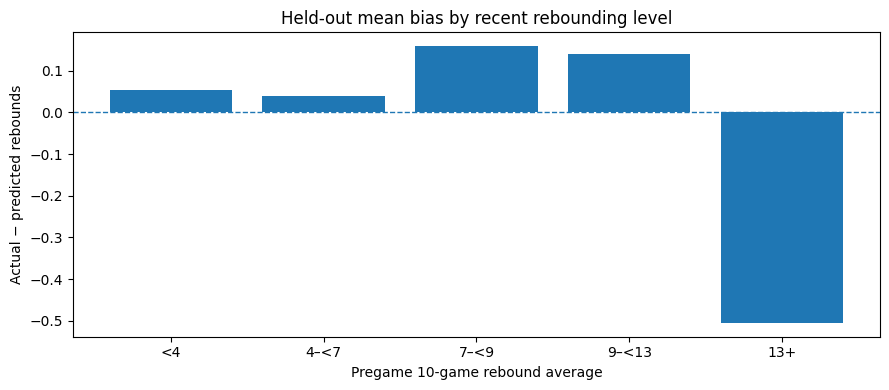

In [ ]:
# ============================================================
# 10.1 MEAN RESIDUALS BY PREGAME REBOUND AVERAGE
# ============================================================
import matplotlib.pyplot as plt

REB_BUCKET_EDGES = [-np.inf, 4, 7, 9, 13, np.inf]
REB_BUCKET_LABELS = ["<4", "4–<7", "7–<9", "9–<13", "13+"]

def mean_bias_diagnostics(features, actual, predicted, *, label):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    if len(features) != len(actual) or len(actual) != len(predicted):
        raise ValueError("Prediction and feature row counts differ")
    out = pd.DataFrame({
        "actual": actual,
        "predicted": predicted,
        "recent_10": pd.to_numeric(features["reboundsTotal_avg10"], errors="coerce").to_numpy(),
    })
    out["residual"] = out["actual"] - out["predicted"]
    out["bucket"] = pd.cut(out["recent_10"], bins=REB_BUCKET_EDGES,
                           labels=REB_BUCKET_LABELS, right=False)
    grouped = (out.groupby("bucket", observed=False)
                 .agg(n=("residual", "size"),
                      actual_mean=("actual", "mean"),
                      predicted_mean=("predicted", "mean"),
                      bias_actual_minus_pred=("residual", "mean"),
                      MAE=("residual", lambda x: x.abs().mean()),
                      RMSE=("residual", lambda x: np.sqrt(np.mean(np.square(x)))))
                 .reset_index())
    print(f"{label}: overall mean bias = {out.residual.mean():+.3f} rebounds "
          f"(positive = underprediction), MAE = {out.residual.abs().mean():.3f}")
    display(grouped)
    return out, grouped

# Validation predictions were generated by the training-only model.
val_mean_bias, val_bias_buckets = mean_bias_diagnostics(
    X_val, y_val, val_mu, label="Validation: probabilistic mean model")
# Final mean model was refitted on train+validation and evaluated on untouched test.
test_mean_bias, test_bias_buckets = mean_bias_diagnostics(
    X_test, y_test, test_mu, label="Held-out test: probabilistic mean model")

fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(0, linewidth=1, linestyle="--")
ax.bar(test_bias_buckets["bucket"].astype(str),
       test_bias_buckets["bias_actual_minus_pred"])
ax.set(xlabel="Pregame 10-game rebound average", ylabel="Actual − predicted rebounds",
       title="Held-out mean bias by recent rebounding level")
plt.tight_layout()
plt.show()


### 10.2 Probability calibration for both sides

A 70% predicted Under should occur approximately 70% of the time **among comparable, out-of-sample predictions**. Evaluate a range of common half-point lines, including **11.5**, and report probability buckets with sample sizes. Over and Under results for the same line are complementary and **not independent bets**. Calibration is descriptive; avoid selecting a new distribution based on the held-out test.

Held-out test: probability-bucket calibration


,side,probability_bin,n,predicted_win_rate,actual_win_rate,gap
0,over,"(-0.001, 0.1]",661013,0.018579,0.019364,0.000785
1,over,"(0.1, 0.2]",90301,0.145524,0.148060,0.002536
2,over,"(0.2, 0.3]",60170,0.245809,0.249659,0.003850
3,over,"(0.3, 0.4]",44387,0.348439,0.366661,0.018223
4,over,"(0.4, 0.5]",38802,0.449708,0.472038,0.022330
5,over,"(0.5, 0.6]",28140,0.553002,0.568124,0.015122
6,over,"(0.6, 0.7]",28589,0.649466,0.667879,0.018413
7,over,"(0.7, 0.8]",27426,0.749405,0.764785,0.015380
8,over,"(0.8, 0.9]",19881,0.840903,0.856798,0.015895
9,over,"(0.9, 1.0]",23970,0.951115,0.950188,-0.000927


Held-out test: calibration by sportsbook line


,side,line,n,predicted_win_rate,actual_win_rate,gap
0,over,2.5,113631,0.606001,0.618256,0.012255
1,over,4.5,113631,0.357897,0.369767,0.011870
2,over,6.5,113631,0.196792,0.202559,0.005767
3,over,8.5,113631,0.104221,0.107541,0.003320
4,over,9.5,113631,0.075124,0.078438,0.003315
5,over,10.5,113631,0.053828,0.055575,0.001746
6,over,11.5,113631,0.038328,0.039276,0.000949
7,over,12.5,113631,0.027104,0.026885,-0.000219
8,over,14.5,113631,0.013249,0.012285,-0.000964
9,under,2.5,113631,0.393999,0.381744,-0.012255


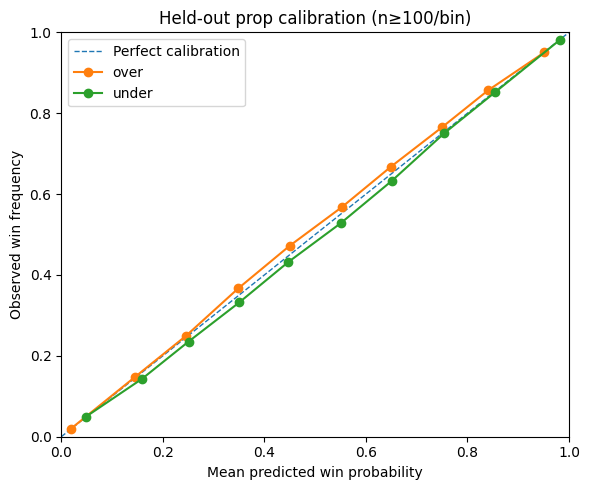

In [ ]:
# ============================================================
# 10.2 LINE- AND PROBABILITY-BUCKET CALIBRATION
# ============================================================
CALIBRATION_LINES = np.array([2.5, 4.5, 6.5, 8.5, 9.5, 10.5, 11.5, 12.5, 14.5])
PROB_BINS = np.linspace(0, 1, 11)

def build_prop_calibration(actual, mu, kind, alpha, lines=CALIBRATION_LINES):
    actual = np.asarray(actual, dtype=float)
    mu = np.asarray(mu, dtype=float)
    if actual.shape != mu.shape:
        raise ValueError("actual and mu must have identical shapes")
    parts = []
    for line in lines:
        probs = prop_probabilities(mu, line, distribution=kind, alpha=alpha)
        for side in ("under", "over"):
            p = np.asarray(probs[side], dtype=float)
            won = (actual < line) if side == "under" else (actual > line)
            parts.append(pd.DataFrame({"line": float(line), "side": side,
                                       "predicted_probability": p,
                                       "won": won.astype(int)}))
    return pd.concat(parts, ignore_index=True)

def calibration_summary(calibration):
    data = calibration.copy()
    data["probability_bin"] = pd.cut(
        data["predicted_probability"], PROB_BINS, include_lowest=True)
    return (data.groupby(["side", "probability_bin"], observed=False)
            .agg(n=("won", "size"), predicted_win_rate=("predicted_probability", "mean"),
                 actual_win_rate=("won", "mean"))
            .assign(gap=lambda x: x.actual_win_rate - x.predicted_win_rate)
            .reset_index())

def line_summary(calibration):
    return (calibration.groupby(["side", "line"], observed=True)
            .agg(n=("won", "size"), predicted_win_rate=("predicted_probability", "mean"),
                 actual_win_rate=("won", "mean"))
            .assign(gap=lambda x: x.actual_win_rate - x.predicted_win_rate)
            .reset_index())

# IMPORTANT: the final test is reporting only; it is not used for selection.
test_calibration = build_prop_calibration(
    y_test, test_mu, final_kind, test_alpha)
test_probability_buckets = calibration_summary(test_calibration)
test_line_calibration = line_summary(test_calibration)
print("Held-out test: probability-bucket calibration")
display(test_probability_buckets)
print("Held-out test: calibration by sportsbook line")
display(test_line_calibration)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", linewidth=1, label="Perfect calibration")
for side, sub in test_probability_buckets.groupby("side"):
    sub = sub.loc[sub["n"] >= 100].dropna(subset=["predicted_win_rate", "actual_win_rate"])
    ax.plot(sub.predicted_win_rate, sub.actual_win_rate, marker="o", label=side)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted win probability",
       ylabel="Observed win frequency", title="Held-out prop calibration (n≥100/bin)")
ax.legend()
plt.tight_layout()
plt.show()


### 10.3 High-rebound players and extreme Under probabilities

This focuses on players whose **pregame 10-game average is at least 9 rebounds**. Report observed outcomes for model Under probabilities of 70–80%, 80–90%, and 90–100%. Small buckets are not conclusive; inspect `n` before acting on a result. The **11.5 line** is included explicitly.

In [ ]:
# ============================================================
# 10.3 HIGH-REBOUND PLAYER CALIBRATION AND 11.5 CASE STUDY
# ============================================================
recent10_test = pd.to_numeric(X_test["reboundsTotal_avg10"], errors="coerce").to_numpy()
base_n = len(y_test)
high_rebound = np.isfinite(recent10_test) & (recent10_test >= 9)

under_rows = test_calibration.loc[test_calibration.side == "under"].copy()
# build_prop_calibration creates one full set of player rows per line per side.
under_rows["recent10"] = np.tile(recent10_test, len(CALIBRATION_LINES))
under_rows = under_rows.loc[under_rows.recent10 >= 9].copy()
under_rows["confidence"] = pd.cut(
    under_rows.predicted_probability, bins=[0.7, 0.8, 0.9, 1.0],
    include_lowest=True, labels=["70–80%", "80–90%", "90–100%"])
high_confidence = (under_rows.dropna(subset=["confidence"])
    .groupby("confidence", observed=False)
    .agg(n=("won", "size"), predicted_win_rate=("predicted_probability", "mean"),
         observed_win_rate=("won", "mean"))
    .assign(gap=lambda x: x.observed_win_rate - x.predicted_win_rate)
    .reset_index())
print(f"High-rebound player-games in test: {high_rebound.sum():,} / {base_n:,}")
display(high_confidence)
print("11.5 rebound line, high-rebound players only:")
display(line_summary(under_rows.loc[under_rows.line == 11.5]))

# A Jokić-style mean discrepancy is NOT sufficient to establish systematic bias.
# Quantify how often the model projects >=2 rebounds below a recent average.
large_gap = high_rebound & ((recent10_test - test_mu) >= 2)
print(f"Player-games with recent10>=9 and projection >=2 below recent10: "
      f"{large_gap.sum():,}")
if large_gap.any():
    residual = y_test.to_numpy() - test_mu
    print(f"Those rows: actual mean={y_test.to_numpy()[large_gap].mean():.3f}, "
          f"predicted mean={test_mu[large_gap].mean():.3f}, "
          f"bias={residual[large_gap].mean():+.3f}, "
          f"MAE={np.abs(residual[large_gap]).mean():.3f}")


High-rebound player-games in test: 6,643 / 113,631


,confidence,n,predicted_win_rate,observed_win_rate,gap
0,70–80%,6722,0.750069,0.734752,-0.015317
1,80–90%,5566,0.845335,0.835968,-0.009367
2,90–100%,2750,0.923714,0.922545,-0.001169


11.5 rebound line, high-rebound players only:


,side,line,n,predicted_win_rate,actual_win_rate,gap
0,under,11.5,6643,0.659124,0.637664,-0.02146


Player-games with recent10>=9 and projection >=2 below recent10: 260
Those rows: actual mean=10.238, predicted mean=9.439, bias=+0.799, MAE=3.207


### 10.4 Diagnose an individual projection with SHAP

Supply the **exact pregame feature row** used in production, in the same column order as `PROB_FEATURES`. The notebook cannot reconstruct the Toronto–Denver Jokić prediction from the example odds row alone. This cell explains the fitted **mean model**, not sportsbook blending or the negative-binomial pricing layer.

In [ ]:
# ============================================================
# 10.4 OPTIONAL EXACT-ROW FEATURE ATTRIBUTION
# ============================================================
# Set JOKIC_FEATURE_ROW to a one-row pandas DataFrame with the exact
# PROB_FEATURES values from the production prediction, then run this cell.
JOKIC_FEATURE_ROW = None

if JOKIC_FEATURE_ROW is not None:
    import shap
    row = JOKIC_FEATURE_ROW.reindex(columns=PROB_FEATURES).copy()
    if len(row) != 1:
        raise ValueError("Supply exactly one prediction row")
    row = row.apply(pd.to_numeric, errors="coerce").astype("float32")
    explainer = shap.TreeExplainer(prob_mean_final)
    explanation = explainer(row)
    attributions = pd.DataFrame({
        "feature": row.columns,
        "feature_value": row.iloc[0].to_numpy(),
        "SHAP_contribution": explanation.values[0],
    }).sort_values("SHAP_contribution")
    print("Model prediction:", float(prob_mean_final.predict(row)[0]))
    print("SHAP reconstruction:", float(np.asarray(explanation.base_values).reshape(-1)[0]
                                        + explanation.values[0].sum()))
    display(attributions)
else:
    print("Skipped: set JOKIC_FEATURE_ROW to the exact production feature row.")


Skipped: set JOKIC_FEATURE_ROW to the exact production feature row.


In [ ]:
# ============================================================
# 10.5 EXPORT DIAGNOSTICS (NO RETRAINING / NO TEST-SET TUNING)
# ============================================================
DIAG_DIR = Path("models/nba_rebounds/v1_probabilistic/diagnostics")
DIAG_DIR.mkdir(parents=True, exist_ok=True)
for name, table in {
    "validation_mean_bias_buckets.csv": val_bias_buckets,
    "test_mean_bias_buckets.csv": test_bias_buckets,
    "test_probability_buckets.csv": test_probability_buckets,
    "test_line_calibration.csv": test_line_calibration,
    "test_high_rebound_under_calibration.csv": high_confidence,
}.items():
    table.to_csv(DIAG_DIR / name, index=False)
print("Saved diagnostic tables to:", DIAG_DIR.resolve())


Saved diagnostic tables to: /content/models/nba_rebounds/v1_probabilistic/diagnostics


In [ ]:
# ============================================================
# 9.6 EXAMPLE: REBOUND PROBABILITIES AND FAIR PRICES
# ============================================================
example_mu = 8.3
example_line = 8.5
example_bookmaker_over = 1.95
example_bookmaker_under = 1.90

example_kind, example_alpha = select_distribution(
    BEST_DISTRIBUTION,
    np.array([example_mu]),
    alpha_final,
    bucket_final,
)
example_probs = prop_probabilities(
    example_mu, example_line, distribution=example_kind,
    alpha=example_alpha,
)
for side, odds in [("over", example_bookmaker_over),
                   ("under", example_bookmaker_under)]:
    p_win = float(np.asarray(example_probs[side]).item())
    p_push = float(np.asarray(example_probs["push"]).item())
    print(f"{side.upper()} {example_line}: win={p_win:.2%}, "
          f"push={p_push:.2%}, fair_odds={float(fair_odds(p_win, p_push)):.3f}, "
          f"EV={float(expected_roi(p_win, p_push, odds)):.2%}")


ValueError: cannot broadcast a non-scalar to a scalar array

In [ ]:
# ============================================================
# 9.7 SAVE PROBABILISTIC REBOUND MODEL
# ============================================================
import json
import joblib
from pathlib import Path

PROB_OUT_DIR = Path("models/nba_rebounds/v1_probabilistic")
PROB_OUT_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(prob_mean_final, PROB_OUT_DIR / "rebounds_mean_lightgbm.joblib")

prob_config = {
    "target": "reboundsTotal",
    "mean_model": PROB_MODEL_NAME,
    "features": PROB_FEATURES,
    "distribution": BEST_DISTRIBUTION,
    "nb2_global_alpha": float(alpha_final),
    "nb2_bucket_edges": [float(v) for v in bucket_final["edges"]],
    "nb2_bucket_alphas": [float(v) for v in bucket_final["alphas"]],
    "ewma_alpha": float(ALPHA),
    "test_scores": {k: float(v) for k, v in selected_test_scores.items()},
    "conditioning": "Player participated; DNP probability not modelled",
    "selection_metric": "Validation mean count NLL",
}
(PROB_OUT_DIR / "probability_config.json").write_text(
    json.dumps(prob_config, indent=2), encoding="utf-8"
)
validation_prob_results.to_csv(PROB_OUT_DIR / "validation_distributions.csv", index=False)
validation_line_diagnostics.to_csv(PROB_OUT_DIR / "validation_lines.csv", index=False)
selected_test_lines.to_csv(PROB_OUT_DIR / "test_lines.csv", index=False)
print("Saved probabilistic model to:", PROB_OUT_DIR.resolve())
